In [1]:
%matplotlib inline
import sys
sys.path.insert(0, "../scripts")


# Hito 2 — Motor Cinemático Inverso (Pieper) y Perfiles LSPB

**Grupo VEVAS** · Susann Baldiviezo C. · Florencia Frigerio · Alejandro Bejarano R. · Benjamín Soruco G.

Robótica IMT-342 · Docente: M.Sc. Ing. Bernardo Quiroga Turdera · Gestión II-2026

---

## Pasaporte de este hito

> *Demostración en Jupyter Notebook de la divergencia analítica de velocidades
> y torques en singularidad ($q_5 = 0$ rad).*
> — Guía Oficial del PFI

Se demuestra en la **sección 5**, con las leyes de escalado ajustadas
numéricamente: $\|\dot{q}\| \sim q_5^{-1}$ y $\tau \sim q_5^{-2}$.

## Convención de unidades

Todas las magnitudes están en **SI**, sin excepción:

| Magnitud | Unidad | Símbolo |
|---|---|---|
| Longitud | metro | m |
| Ángulo articular | radián | rad |
| Velocidad articular | radián por segundo | rad/s |
| Aceleración articular | radián por segundo al cuadrado | rad/s² |
| Masa | kilogramo | kg |
| Inercia | kilogramo metro cuadrado | kg·m² |
| Torque | newton metro | N·m |
| Tiempo | segundo | s |

Los límites del manual de ABB vienen en **grados** y se convierten a radianes
una sola vez, en `fk_irb120.py`. Ningún ángulo en grados circula por el código.

---
# 1. Planteamiento del Problema y Modelo del Robot

## 1.1 El problema

Dada una pose deseada del efector final $T_d \in SE(3)$, encontrar las
configuraciones articulares $\mathbf{q} \in \mathbb{R}^6$ que la alcanzan,
generar una trayectoria temporal suave hacia una de ellas, y predecir el
esfuerzo que los motores deberán realizar para seguirla.

El Hito 1 resolvió el problema **directo**: dado $\mathbf{q}$, hallar $T$.
Este hito resuelve el **inverso** y lo extiende al dominio del tiempo.

Una diferencia estructural separa ambos problemas:

| | Directo (Hito 1) | Inverso (Hito 2) |
|---|---|---|
| Existencia | siempre | sólo si la pose es alcanzable |
| Unicidad | **siempre única** | hasta **8 soluciones** |
| Método | producto de matrices | desacoplamiento analítico |

## 1.2 Modelo cinemático

Se reutiliza sin modificación la tabla Denavit–Hartenberg validada en el
Hito 1 (parametrización de Truc y Lam, 2020), con error de cierre
$2{,}08 \times 10^{-18}$ m frente a las cotas del manual de ABB:

| $i$ | $\theta_i$ | $d_i$ [m] | $a_i$ [m] | $\alpha_i$ [rad] |
|---|---|---|---|---|
| 1 | $q_1$ | 0,290 | 0,000 | $-\pi/2$ |
| 2 | $q_2 - \pi/2$ | 0,000 | 0,270 | $0$ |
| 3 | $q_3$ | 0,000 | 0,070 | $-\pi/2$ |
| 4 | $q_4$ | 0,302 | 0,000 | $+\pi/2$ |
| 5 | $q_5$ | 0,000 | 0,000 | $-\pi/2$ |
| 6 | $q_6$ | 0,072 | 0,000 | $0$ |

**No se vuelve a escribir la tabla en este notebook.** Se importa del módulo
del Hito 1: una sola fuente de verdad. Si un parámetro cambia, todo el
pipeline se actualiza solo.

## 1.3 La propiedad que lo hace posible

Las juntas 4, 5 y 6 forman una **muñeca esférica**: sus tres ejes se cortan en
un punto. Geométricamente esto significa $a_4 = a_5 = 0$, y es justamente la
condición que exige el método de Pieper.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from fk_irb120 import DH_TABLE, JOINT_LIMITS, forward_kinematics
from pieper import (pieper, wrist_center, filtrar, elegir, etiquetar,
                    resolver, error_pose, dentro_de_limites)
from jacobiano import (jacobiano, jacobiano_numerico, jacobiano_2r,
                       validacion_manual_q0, medida_manipulabilidad,
                       diagnostico)
from lspb import LSPB, LSPBSincronizado, comprobar_continuidad
from dinamica import (M_matriz, C_matriz, g_vector, torque,
                      torque_trayectoria, energia)
import singularidad as sg
import graficas as gr

np.set_printoptions(precision=6, suppress=True)

print("Tabla D-H importada del Hito 1  (theta_off, d, a, alpha)")
for i, (off, d, a, al) in enumerate(DH_TABLE, 1):
    print(f"  J{i}:  off = {off:+.6f} rad   d = {d:.3f} m   "
          f"a = {a:.3f} m   alpha = {al:+.6f} rad")

print("\nLimites articulares [rad]")
for i, (lo, hi) in enumerate(JOINT_LIMITS, 1):
    print(f"  J{i}:  [{lo:+.6f}, {hi:+.6f}]   "
          f"= [{np.degrees(lo):+7.1f}, {np.degrees(hi):+7.1f}] grados")

Tabla D-H importada del Hito 1  (theta_off, d, a, alpha)
  J1:  off = +0.000000 rad   d = 0.290 m   a = 0.000 m   alpha = -1.570796 rad
  J2:  off = -1.570796 rad   d = 0.000 m   a = 0.270 m   alpha = +0.000000 rad
  J3:  off = +0.000000 rad   d = 0.000 m   a = 0.070 m   alpha = -1.570796 rad
  J4:  off = +0.000000 rad   d = 0.302 m   a = 0.000 m   alpha = +1.570796 rad
  J5:  off = +0.000000 rad   d = 0.000 m   a = 0.000 m   alpha = -1.570796 rad
  J6:  off = +0.000000 rad   d = 0.072 m   a = 0.000 m   alpha = +0.000000 rad

Limites articulares [rad]
  J1:  [-2.879793, +2.879793]   = [ -165.0,  +165.0] grados
  J2:  [-1.919862, +1.919862]   = [ -110.0,  +110.0] grados
  J3:  [-1.919862, +1.221730]   = [ -110.0,   +70.0] grados
  J4:  [-2.792527, +2.792527]   = [ -160.0,  +160.0] grados
  J5:  [-2.094395, +2.094395]   = [ -120.0,  +120.0] grados
  J6:  [-6.981317, +6.981317]   = [ -400.0,  +400.0] grados


---
# 2. Cinemática Inversa Analítica (Método de Pieper)

## 2.1 El desacoplamiento

Resolver seis incógnitas acopladas simultáneamente es inabordable
analíticamente. Pieper observó que si los tres últimos ejes se cortan en un
punto, el problema **se parte en dos de tres incógnitas**:

$$\underbrace{p_W \longrightarrow (q_1, q_2, q_3)}_{\text{posición}}
\qquad
\underbrace{{}^3R_6 \longrightarrow (q_4, q_5, q_6)}_{\text{orientación}}$$

La clave es que el **centro de muñeca** $p_W$ no depende de $q_4, q_5, q_6$:
esas juntas sólo reorientan en torno a ese punto fijo.

## 2.2 Centro de muñeca

La junta 6 únicamente traslada $d_6$ a lo largo de su propio eje $z_6$. Por
tanto, retrocediendo desde la brida:

$$\boxed{\;p_W = p_d - d_6\, z_6^d\;}, \qquad z_6^d = R_d \begin{bmatrix}0\\0\\1\end{bmatrix}$$

**Por qué la orientación modifica el centro de muñeca:** $z_6^d$ es la tercera
columna de $R_d$. Dos poses con idéntica posición $p_d$ pero orientación
distinta tienen centros de muñeca distintos, porque el vector $d_6 z_6^d$ que
hay que retroceder apunta en otra dirección.

## 2.3 Subproblema de posición

Desarrollando simbólicamente la cadena $\,{}^0T_4$ se obtiene una estructura
notablemente limpia:

$$r = a_2 \sin q_2 + a_3 \sin(q_2+q_3) + d_4 \cos(q_2+q_3)$$
$$s = z_W - d_1 = a_2 \cos q_2 + a_3 \cos(q_2+q_3) - d_4 \sin(q_2+q_3)$$

donde $r = \sqrt{x_W^2 + y_W^2}$ es el radio en el plano del brazo.

**El truco del eslabón equivalente.** Los términos $a_3$ y $d_4$ aparecen
siempre en la combinación $a_3\sin\phi + d_4\cos\phi$. Definiendo

$$k = \sqrt{a_3^2 + d_4^2}, \qquad \psi = \operatorname{atan2}(d_4,\, a_3)$$

esa combinación colapsa a $k\sin(\phi + \psi)$, y el manipulador se vuelve un
**2R planar** de eslabones $a_2$ y $k$. El problema se reduce al caso clásico:

$$\cos\gamma = \frac{r^2 + s^2 - a_2^2 - k^2}{2 a_2 k}, \qquad \gamma = q_3 + \psi$$

$$q_3 = \gamma - \psi, \qquad
q_2 = \operatorname{atan2}\big(Ur - Vs,\; Vr + Us\big)$$

con $U = a_2 + k\cos\gamma$ y $V = k\sin\gamma$.

## 2.4 Enumeración de las 8 ramas

Tres signos independientes generan $2^3 = 8$ soluciones:

| Signo | Interpretación geométrica |
|---|---|
| $q_1$ o $q_1 + \pi$ | **hombro** frontal / posterior |
| $\gamma = \pm\arccos(D)$ | **codo** arriba / abajo |
| $q_5 = \pm\arccos(R_{33})$ | **muñeca** no invertida / invertida |

Los dos signos de $\arccos$ **no son un artificio algebraico**: corresponden a
posturas físicamente distintas del triángulo hombro–codo–muñeca, ambas
alcanzando el mismo punto.

## 2.5 Por qué `atan2` y no `arctan`

$\arctan(y/x)$ devuelve un ángulo en $(-\pi/2, \pi/2)$ y **pierde el
cuadrante**: no distingue $(1,1)$ de $(-1,-1)$, porque ambos dan cociente $+1$.
`atan2(y, x)` recibe los dos argumentos por separado, conserva sus signos y
cubre el círculo completo $(-\pi, \pi]$. Con `arctan` la mitad de las ramas
sería inalcanzable.

In [3]:
# Demostracion del desacoplamiento: el centro de muneca NO depende de q4,q5,q6
q_a = np.array([0.4, -0.6, 0.5,  0.3,  0.7, -0.2])
q_b = np.array([0.4, -0.6, 0.5, -1.1, -0.4,  2.0])   # mismas 3 primeras

pw_a = wrist_center(forward_kinematics(q_a))
pw_b = wrist_center(forward_kinematics(q_b))

print("q1,q2,q3 identicos; q4,q5,q6 distintos\n")
print(f"  p_W (config. a) = {pw_a}")
print(f"  p_W (config. b) = {pw_b}")
print(f"  diferencia      = {np.linalg.norm(pw_a - pw_b):.3e} m")
print("\n=> El centro de muneca depende SOLO de las tres primeras juntas.")
print("   Ese es el desacoplamiento que hace posible el metodo.")

q1,q2,q3 identicos; q4,q5,q6 distintos

  p_W (config. a) = [0.129915 0.054927 0.612641]
  p_W (config. b) = [0.129915 0.054927 0.612641]
  diferencia      = 6.939e-18 m

=> El centro de muneca depende SOLO de las tres primeras juntas.
   Ese es el desacoplamiento que hace posible el metodo.


In [4]:
# Las 8 ramas de una pose concreta
q_real = np.array([0.4, -0.6, 0.5, 0.3, 0.7, -0.2])
T_d = forward_kinematics(q_real)

print("Pose objetivo T_d generada desde q_real =", q_real)
print(f"  p_d = {T_d[:3, 3]} m")
print(f"  p_W = {wrist_center(T_d)} m\n")

ramas = pieper(T_d)
print(f"{'#':>2}  {'q [rad]':^52}  {'dE [m]':>10}  rama")
print("-" * 104)
for i, q in enumerate(ramas, 1):
    ep, _ = error_pose(q, T_d)
    print(f"{i:>2}  {str(np.round(q, 4)):^52}  {ep:>10.2e}  {etiquetar(q)}")

print(f"\nTotal: {len(ramas)} ramas analiticas = 2 (hombro) x 2 (codo) x 2 (muneca)")

Pose objetivo T_d generada desde q_real = [ 0.4 -0.6  0.5  0.3  0.7 -0.2]
  p_d = [0.17912  0.090613 0.574048] m
  p_W = [0.129915 0.054927 0.612641] m

 #                        q [rad]                             dE [m]  rama
--------------------------------------------------------------------------------------------------------
 1            [ 0.4 -0.6  0.5  0.3  0.7 -0.2]               1.80e-16  codo arriba / muneca no invertida / hombro frontal
 2   [ 0.4    -0.6     0.5    -2.8416 -0.7     2.9416]      1.80e-16  codo arriba / muneca invertida / hombro frontal
 3   [ 0.4     1.4243 -3.1861  0.2635  2.3218  0.2144]      2.78e-17  codo abajo / muneca no invertida / hombro frontal
 4   [ 0.4     1.4243 -3.1861 -2.8781 -2.3218 -2.9272]      3.10e-17  codo abajo / muneca invertida / hombro frontal
 5   [-2.7416 -1.4243  0.5    -2.623   2.7474  0.5173]      5.55e-17  codo arriba / muneca no invertida / hombro posterior
 6   [-2.7416 -1.4243  0.5     0.5186 -2.7474 -2.6243]      5.55e-17

## 2.6 Filtrado físico de ramas

Las 8 ramas son matemáticamente correctas, pero **no todas son ejecutables**.
Se aplican tres filtros en orden:

1. **Numérico** — descarta valores no finitos (pose fuera del espacio de
   trabajo alcanzable).
2. **Cinemático** — verifica $T_0^6(\mathbf{q}) \approx T_d$. Una rama que no
   reproduce la pose es un error algebraico, no una alternativa.
3. **Físico** — descarta las que violan los límites del datasheet de ABB.

El criterio de **selección** entre las supervivientes es el mínimo
desplazamiento articular ponderado:

$$k^\star = \arg\min_k \sum_{i=1}^{6} w_i \left(q_i^{(k)} - q_i^{\text{actual}}\right)^2$$

Los pesos $w = [4, 3, 2, 1, 1, 0{,}5]$ penalizan más el movimiento de las
juntas proximales: girar la base arrastra todo el brazo, mientras que rotar la
brida casi no cuesta. Sin pesos, el criterio elegiría ramas que hacen girar
media vuelta la base para ahorrar unos grados en la muñeca.

In [5]:
q_sel, admisibles, rechazadas = resolver(T_d, q_actual=np.zeros(6), verbose=True)

print(f"\nRama seleccionada: {np.round(q_sel, 6)}")
print(f"Coincide con la original: {np.allclose(q_sel, q_real, atol=1e-9)}")

  ramas calculadas  8
  admisibles        1
  rechazadas        7
     - fuera de limites: J4
     - fuera de limites: J3, J5
     - fuera de limites: J3, J4, J5
     - fuera de limites: J5
     - fuera de limites: J5
     - fuera de limites: J3, J4
     - fuera de limites: J3
  elegida           codo arriba / muneca no invertida / hombro frontal  (costo 2.8200)

Rama seleccionada: [ 0.4 -0.6  0.5  0.3  0.7 -0.2]
Coincide con la original: True


---
# 3. Verificación FK

## 3.1 La lógica de la validación

Resolver la cinemática inversa produce *candidatos*. La única prueba de que un
candidato es correcto consiste en **volver a aplicarle la cinemática directa**
y comprobar que recupera la pose de partida:

$$T_0^6\big(\mathbf{q}^{(k)}\big) \;\stackrel{?}{\approx}\; T_d$$

El argumento es que la cinemática directa es un mapa **determinista y ya
validado** (Hito 1, $\Delta E = 2{,}46\times 10^{-10}$ m contra el árbol TF de
ROS). Si al componer ambos mapas se recupera el punto de partida, la inversa es
correcta sobre ese punto. Es verificación por composición, no por confianza.

## 3.2 Métricas

Se valida la pose **completa**, no sólo la posición:

$$\varepsilon_p = \|p_{FK} - p_d\|_2 \;[\mathrm{m}], \qquad
\varepsilon_R = \big\|R_{FK}^{\top} R_d - I\big\|_F$$

La métrica angular usa que $R^{-1} = R^{\top}$ en $SO(3)$: el producto da la
identidad **si y sólo si** ambas rotaciones coinciden. Así se verifican los 6
grados de libertad y no sólo 3.

In [6]:
# Validacion masiva: 2000 poses aleatorias dentro de los limites
rng = np.random.default_rng(3)
peor_p = peor_R = 0.0
sin_solucion = 0
conteo_ramas = []

for _ in range(2000):
    q = rng.uniform(JOINT_LIMITS[:, 0], JOINT_LIMITS[:, 1])
    Td = forward_kinematics(q)
    validas = [s for s in pieper(Td) if max(error_pose(s, Td)) < 1e-6]
    conteo_ramas.append(len(validas))
    if not validas:
        sin_solucion += 1
        continue
    for s in validas:
        ep, eR = error_pose(s, Td)
        peor_p, peor_R = max(peor_p, ep), max(peor_R, eR)

print("   Verificacion FK sobre 2000 poses aleatorias\n")
print(f"  ramas validas por pose (media)   {np.mean(conteo_ramas):.2f}")
print(f"  poses sin solucion               {sin_solucion}")
print(f"  error posicional maximo          {peor_p:.3e} m")
print(f"  error de orientacion maximo      {peor_R:.3e}")
print(f"\n  RESULTADO: {'APROBADO' if peor_p < 1e-9 and sin_solucion == 0 else 'REVISAR'}")
print(f"  El residuo es epsilon de maquina en float64, no error de modelo.")

   Verificacion FK sobre 2000 poses aleatorias

  ramas validas por pose (media)   8.00
  poses sin solucion               0
  error posicional maximo          3.679e-15 m
  error de orientacion maximo      7.247e-14

  RESULTADO: APROBADO
  El residuo es epsilon de maquina en float64, no error de modelo.


---
# 4. Jacobiano Geométrico

## 4.1 Qué es y qué significa

El Jacobiano es el mapa lineal **instantáneo** entre velocidades articulares y
velocidad del efector:

$$\begin{bmatrix} v \\ \omega \end{bmatrix} = J(\mathbf{q})\, \dot{\mathbf{q}},
\qquad J \in \mathbb{R}^{6\times 6}$$

**Interpretación física columna por columna:** la columna $i$-ésima es la
velocidad del efector cuando *sólo* la junta $i$ gira a velocidad unitaria. Es
decir, cada columna es el **brazo de palanca** de esa junta sobre el efector.

## 4.2 Construcción

Para una junta de revolución $i$, el eje de giro es $z_{i-1}$ y el punto de
aplicación $O_{i-1}$. La velocidad que induce en el efector es el producto
vectorial clásico del sólido rígido:

$$J_{v_i} = z_{i-1} \times (p_e - p_{i-1}), \qquad J_{\omega_i} = z_{i-1}$$

Todo lo necesario —$z_{i-1}$ y $p_{i-1}$— sale de las matrices
$\,{}^0T_i$ que ya calcula la cinemática directa.

## 4.3 Validación manual (exigida por la rúbrica)

En $\mathbf{q} = \mathbf{0}$ la geometría se conoce sin calcular: la brida está
en $p_e = [0{,}374,\ 0,\ 0{,}630]$ m y el primer eje es $z_0 = [0,0,1]$ con
origen en $O_0 = [0,0,0]$. Entonces:

$$J_{v_1} = \begin{bmatrix}0\\0\\1\end{bmatrix} \times
\begin{bmatrix}0{,}374\\0\\0{,}630\end{bmatrix}
= \begin{bmatrix}0\cdot 0{,}630 - 1\cdot 0\\ 1\cdot 0{,}374 - 0\cdot 0{,}630\\ 0\end{bmatrix}
= \begin{bmatrix}0\\0{,}374\\0\end{bmatrix}$$

**Lectura física:** girar la base a 1 rad/s mueve la brida a 0,374 m/s en
dirección $+y$ — exactamente su distancia al eje de giro. La columna del
Jacobiano *es* el brazo de palanca.

In [7]:
col_codigo, col_mano, err = validacion_manual_q0()
print("   Validacion manual: primera columna de J en q = 0\n")
print(f"  calculada por el codigo   {np.round(col_codigo, 6)}")
print(f"  calculada a mano          {np.round(col_mano, 6)}")
print(f"  discrepancia              {err:.3e}")
print("\n  Las 3 primeras componentes son v [m/s], las 3 ultimas omega [rad/s].")

   Validacion manual: primera columna de J en q = 0

  calculada por el codigo   [-0.     0.374  0.     0.     0.     1.   ]
  calculada a mano          [0.    0.374 0.    0.    0.    1.   ]
  discrepancia              2.082e-18

  Las 3 primeras componentes son v [m/s], las 3 ultimas omega [rad/s].


In [8]:
# Segunda validacion: contra diferencias finitas, en configuraciones aleatorias
rng = np.random.default_rng(11)
peor = 0.0
for _ in range(300):
    q = rng.uniform(-1.5, 1.5, 6)
    peor = max(peor, np.abs(jacobiano(q) - jacobiano_numerico(q)).max())

print(f"   Jacobiano analitico vs. diferencias finitas (300 configuraciones)\n")
print(f"  discrepancia maxima   {peor:.3e}")
print(f"  RESULTADO: {'OK' if peor < 1e-5 else 'REVISAR'}")
print("\n  El residuo ~1e-8 es el error de truncamiento de la diferencia")
print("  finita (paso h = 1e-7), no un error del Jacobiano analitico.")

   Jacobiano analitico vs. diferencias finitas (300 configuraciones)

  discrepancia maxima   3.249e-08
  RESULTADO: OK

  El residuo ~1e-8 es el error de truncamiento de la diferencia
  finita (paso h = 1e-7), no un error del Jacobiano analitico.


In [9]:
# Tercera validacion: el 2R planar de clase, con formula cerrada conocida
print("   Contraste con el 2R planar:  det(J_p) = a1 a2 sin(q2)\n")
print(f"  {'q2 [rad]':>10}  {'det codigo':>12}  {'det formula':>12}  {'rango':>6}")
for q2 in [np.pi/2, np.pi/4, 0.1, 0.0]:
    J2 = jacobiano_2r(0.0, q2)
    print(f"  {q2:>10.4f}  {np.linalg.det(J2):>12.6f}  {np.sin(q2):>12.6f}  "
          f"{np.linalg.matrix_rank(J2):>6d}")
print("\n  En q2 = 0 el brazo esta estirado: las dos columnas se vuelven")
print("  paralelas, el rango cae a 1 y se pierde el movimiento radial.")

   Contraste con el 2R planar:  det(J_p) = a1 a2 sin(q2)

    q2 [rad]    det codigo   det formula   rango
      1.5708      1.000000      1.000000       2
      0.7854      0.707107      0.707107       2
      0.1000      0.099833      0.099833       2
      0.0000      0.000000      0.000000       1

  En q2 = 0 el brazo esta estirado: las dos columnas se vuelven
  paralelas, el rango cae a 1 y se pierde el movimiento radial.


---
# 5. Análisis de Singularidades — **PASAPORTE DEL HITO**

## 5.1 Definición

Una configuración es **singular** cuando el Jacobiano pierde rango:

$$\operatorname{rank} J(\mathbf{q}) < \min(m, n)$$

Ésta es la definición **universal**. El criterio $\det J = 0$ es un *caso
particular* válido sólo si $J$ es cuadrado; para un robot redundante o una
tarea de dimensión reducida, el determinante ni siquiera está definido y hay
que recurrir al rango.

## 5.2 La singularidad de muñeca del IRB 120

Cuando $q_5 = 0$, los ejes $z_3$ y $z_5$ se vuelven **colineales**: las juntas
4 y 6 giran en torno a la misma recta. Dos actuadores producen el mismo
movimiento, de modo que el robot conserva 6 motores pero sólo 5 grados de
libertad instantáneos.

## 5.3 Por qué la velocidad diverge

El control cartesiano requiere invertir el mapa:

$$\dot{\mathbf{q}} = J^{-1}(\mathbf{q})\, \dot{x}_d$$

Mediante la descomposición en valores singulares $J = U\Sigma V^{\top}$:

$$\|\dot{\mathbf{q}}\| \;\geq\; \frac{\|\dot{x}_d\|}{\sigma_{\min}(J)}$$

Como $\sigma_{\min} \to 0$ linealmente con $q_5$, la velocidad articular
exigida crece **sin cota**. Para el IRB 120 el escalado resulta

$$\boxed{\;\|\dot{\mathbf{q}}\| \sim \frac{C}{q_5}\;}$$

## 5.4 Por qué el torque también diverge

Si el robot se aproxima a la singularidad con velocidad constante
$\dot{q}_5 = v_5$, por regla de la cadena:

$$\ddot{q}_i = \frac{d\dot{q}_i}{dt}
= \frac{\partial \dot{q}_i}{\partial q_5}\, v_5
\sim -\frac{C\,v_5}{q_5^{2}}$$

y como $\tau = M\ddot{q} + C\dot{q} + g$, el torque hereda esa divergencia:

$$\boxed{\;\tau \sim \frac{1}{q_5^{2}}\;}$$

## 5.5 Advertencia conceptual obligatoria

El docente señala explícitamente que **singularidad cinemática $\neq$ torque
alto**. Esta demostración **no lo contradice**, y la distinción es esencial:

- La divergencia aquí es **indirecta**: la singularidad hace divergir
  $\dot{q}$ por cinemática diferencial inversa; $\ddot{q}$ diverge como
  derivada de $\dot{q}$; y recién entonces $\tau$ hereda la divergencia.
- La singularidad **no produce torque**: produce velocidad articular infinita,
  y *ésa* produce torque infinito.
- A la inversa, una postura perfectamente **regular** puede exigir un torque
  gravitatorio enorme, sin singularidad alguna. Se muestra el contraejemplo.

En una ley de potencia $y = A\,x^{m}$, tomar logaritmos da
$\log y = m \log x + \log A$: una **recta de pendiente $m$**. Por eso el ajuste
log-log es la prueba cuantitativa de que la divergencia es analítica y no un
artefacto numérico.

In [10]:
# 5.a  Que direccion de tarea se pierde exactamente
q_base = np.array([0.3, 0.5, -0.4, 0.2, 0.0, 0.1])
q_sing = q_base.copy(); q_sing[4] = 0.0

u, s_min = sg.direccion_perdida(q_sing)
J_s = jacobiano(q_sing)

print("   Caracterizacion de la singularidad q5 = 0\n")
print(f"  rango J          {np.linalg.matrix_rank(J_s, tol=1e-8)}  (nominal 6)")
print(f"  det J            {np.linalg.det(J_s):+.3e}")
print(f"  sigma_min        {s_min:.3e}")
print(f"\n  Direccion de tarea perdida (vector singular izquierdo):")
print(f"    lineal  [m/s]    {np.round(u[:3], 4)}")
print(f"    angular [rad/s]  {np.round(u[3:], 4)}")
print(f"\n  Norma de la parte angular: {np.linalg.norm(u[3:]):.4f}")
print("  La componente perdida es una ROTACION, no una traslacion:")
print("  la muneca no puede reorientarse instantaneamente en ese eje.")

   Caracterizacion de la singularidad q5 = 0

  rango J          5  (nominal 6)
  det J            +3.863e-18
  sigma_min        9.778e-18

  Direccion de tarea perdida (vector singular izquierdo):
    lineal  [m/s]    [ 0.1124 -0.85   -0.2632]
    angular [rad/s]  [ 0.0693 -0.0781  0.4299]

  Norma de la parte angular: 0.4424
  La componente perdida es una ROTACION, no una traslacion:
  la muneca no puede reorientarse instantaneamente en ese eje.


In [11]:
# 5.b  Barrido: velocidad articular exigida conforme q5 -> 0
xd = np.zeros(6)
xd[3:] = u[3:] / np.linalg.norm(u[3:])    # velocidad angular unitaria [rad/s]

q5_vals = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6])
filas = sg.barrido(q_base, xd, q5_vals)

print("   Velocidad articular para velocidad de tarea unitaria\n")
print(f"  {'q5 [rad]':>10}  {'rango':>5}  {'sigma_min':>11}  "
      f"{'cond(J)':>11}  {'||qd|| [rad/s]':>15}")
print("  " + "-" * 60)
for f in filas:
    print(f"  {f['q5']:>10.0e}  {f['rango']:>5d}  {f['sigma_min']:>11.3e}  "
          f"{f['cond']:>11.3e}  {f['norma_qd']:>15.3e}")

norma_qd = np.array([f["norma_qd"] for f in filas])
m_v, _ = sg.ley_de_escalado(q5_vals, norma_qd)
print(f"\n  Ley ajustada:  ||qd|| ~ q5^({m_v:.4f})")
print(f"  Pendiente -1 => divergencia hiperbolica.  "
      f"{'CONFIRMADO' if abs(m_v + 1) < 0.05 else 'REVISAR'}")
print(f"\n  A q5 = 1e-6 rad el robot necesitaria {norma_qd[-1]:.2e} rad/s,")
print(f"  unas {norma_qd[-1]/4.36:.0e} veces el limite de J1 (4.36 rad/s).")

   Velocidad articular para velocidad de tarea unitaria

    q5 [rad]  rango    sigma_min      cond(J)   ||qd|| [rad/s]
  ------------------------------------------------------------
       1e-01      6    2.680e-02    6.801e+01        1.648e+01
       1e-02      6    2.679e-03    6.810e+02        1.652e+02
       1e-03      6    2.678e-04    6.813e+03        1.652e+03
       1e-04      6    2.678e-05    6.813e+04        1.652e+04
       1e-05      6    2.678e-06    6.813e+05        1.652e+05
       1e-06      6    2.678e-07    6.813e+06        1.652e+06

  Ley ajustada:  ||qd|| ~ q5^(-1.0001)
  Pendiente -1 => divergencia hiperbolica.  CONFIRMADO

  A q5 = 1e-6 rad el robot necesitaria 1.65e+06 rad/s,
  unas 4e+05 veces el limite de J1 (4.36 rad/s).


In [12]:
# 5.c  Torque exigido
taus = sg.torque_muneca(q_base, xd, q5_vals, v5=1.0)
m_t, _ = sg.ley_de_escalado(q5_vals, taus)

print("   Torque inercial de muneca (aproximacion por rotor desacoplado)\n")
print(f"  {'q5 [rad]':>10}  {'|tau|max [N.m]':>16}")
print("  " + "-" * 28)
for q5, t in zip(q5_vals, taus):
    print(f"  {q5:>10.0e}  {t:>16.3e}")

print(f"\n  Ley ajustada:  tau ~ q5^({m_t:.4f})")
print(f"  Pendiente -2 => divergencia cuadratica.  "
      f"{'CONFIRMADO' if abs(m_t + 2) < 0.1 else 'REVISAR'}")
print("\n  NOTA DE ALCANCE: las inercias de rotor son una estimacion")
print("  declarada (ABB no las publica). Lo que se demuestra es la LEY")
print("  de escalado 1/q5^2, no una cifra certificada de torque.")

   Torque inercial de muneca (aproximacion por rotor desacoplado)

    q5 [rad]    |tau|max [N.m]
  ----------------------------
       1e-01         1.407e+00
       1e-02         1.402e+02
       1e-03         1.402e+04
       1e-04         1.402e+06
       1e-05         1.402e+08
       1e-06         1.402e+10

  Ley ajustada:  tau ~ q5^(-1.9997)
  Pendiente -2 => divergencia cuadratica.  CONFIRMADO

  NOTA DE ALCANCE: las inercias de rotor son una estimacion
  declarada (ABB no las publica). Lo que se demuestra es la LEY
  de escalado 1/q5^2, no una cifra certificada de torque.


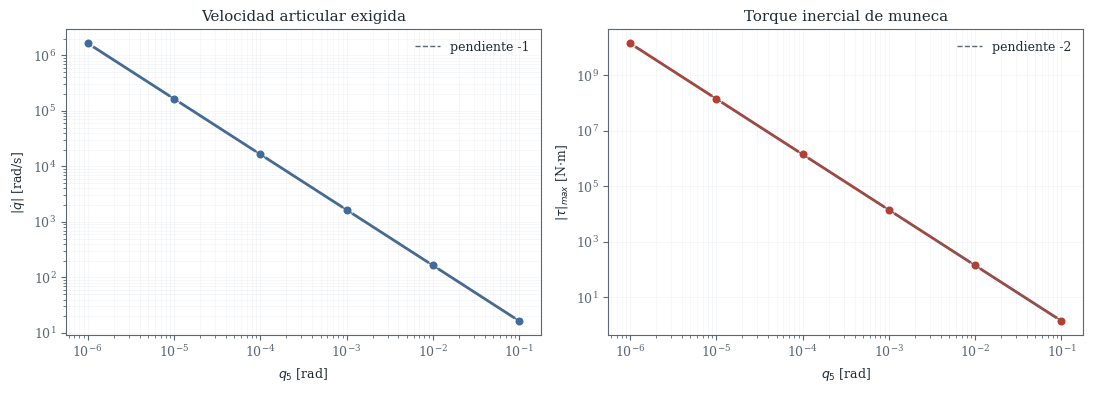

Figura guardada: fig_divergencia.pdf


In [13]:
# 5.d  EL PASAPORTE, en log-log
archivo = gr.divergencia(q5_vals, norma_qd, taus, m_v, m_t,
                         archivo="fig_divergencia.pdf")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, y, m, lab, col in [(axs[0], norma_qd, m_v, r"$\|\dot{q}\|$ [rad/s]", "#3b6ea5"),
                           (axs[1], taus, m_t, r"$|\tau|_{max}$ [N$\cdot$m]", "#c0392b")]:
    ax.loglog(q5_vals, y, "o-", color=col, lw=2, ms=7, mec="white", mew=1.2)
    ax.loglog(q5_vals, y[0]*(q5_vals/q5_vals[0])**round(m), "--",
              color="#5a6672", lw=1, label=f"pendiente {round(m):+d}")
    ax.set_xlabel("$q_5$ [rad]"); ax.set_ylabel(lab)
    ax.legend(frameon=False); ax.grid(which="both", alpha=0.3)
axs[0].set_title("Velocidad articular exigida")
axs[1].set_title("Torque inercial de muneca")
plt.tight_layout(); plt.show()

print(f"Figura guardada: {archivo}")

In [14]:
# 5.e  CONTRAEJEMPLO: singularidad != torque alto
q_reg_6 = np.array([0.0, 0.0, 0.0, 0.0, 1.0, 0.0])   # q5 = 1.0, REGULAR
J_reg = jacobiano(q_reg_6)
tau_g = g_vector(np.array([0.0, 0.0]))               # brazo horizontal

print("   Contraejemplo obligatorio\n")
print(f"  Postura q5 = 1.0 rad  ->  rango J = "
      f"{np.linalg.matrix_rank(J_reg)}, sigma_min = "
      f"{np.linalg.svd(J_reg, compute_uv=False)[-1]:.4f}")
print(f"  Es REGULAR: no hay divergencia de ninguna clase.\n")
print(f"  Torque gravitatorio en esa misma postura: "
      f"{np.abs(tau_g).max():.2f} N.m")
print(f"\n  => Torque elevado SIN singularidad.")
print("  Confirma que ambos fenomenos son independientes: la singularidad")
print("  se define por la MOVILIDAD perdida, no por el esfuerzo requerido.")

   Contraejemplo obligatorio

  Postura q5 = 1.0 rad  ->  rango J = 6, sigma_min = 0.1449
  Es REGULAR: no hay divergencia de ninguna clase.

  Torque gravitatorio en esa misma postura: 24.47 N.m

  => Torque elevado SIN singularidad.
  Confirma que ambos fenomenos son independientes: la singularidad
  se define por la MOVILIDAD perdida, no por el esfuerzo requerido.


---
# 6. Generación de Trayectoria (LSPB)

## 6.1 Por qué no una interpolación lineal

Interpolar linealmente entre $q_0$ y $q_f$ produce velocidad **discontinua** en
los extremos: el motor debería pasar de 0 a $v$ instantáneamente, lo que exige
aceleración infinita y, por tanto, torque infinito. Físicamente imposible.

El perfil **LSPB** (*Linear Segment with Parabolic Blends*) resuelve esto
empalmando dos parábolas con un tramo recto:

| Fase | Intervalo | $\ddot{q}$ |
|---|---|---|
| Aceleración | $0 \le t < t_c$ | $+A$ |
| Crucero | $t_c \le t < T - t_c$ | $0$ |
| Desaceleración | $T - t_c \le t \le T$ | $-A$ |

El resultado es $q(t)$ de clase $C^1$: posición y velocidad continuas,
aceleración discontinua a saltos finitos.

**Por qué un salto en $\ddot{q}$ sí es aceptable y en $\dot{q}$ no:** un salto
de velocidad implica $\ddot{q} \to \infty$ y por tanto $\tau \to \infty$. Un
salto de aceleración implica sólo un salto *finito* de torque, que el motor
entrega sin problema. El precio es un *jerk* infinito, que en modelos básicos
se acepta y en robots de precisión se suaviza con perfiles de orden superior
(S-curve).

## 6.2 Parametrización por tiempo final (hoja de trabajo W09-S01)

Fijando $t_f$ y $\ddot{q}_c$, la condición $q(t_f) = q_f$ da una cuadrática en
$t_c$ cuya solución es:

$$t_c = \frac{t_f}{2} - \frac{1}{2}\sqrt{t_f^2 - \frac{4(q_f - q_i)}{\ddot{q}_c}}$$

**Condición de factibilidad.** El radicando debe ser no negativo:

$$|\ddot{q}_c| \;\geq\; \frac{4\,|q_f - q_i|}{t_f^{2}}$$

Si no se cumple, **no existe** perfil trapezoidal que recorra esa distancia en
ese tiempo con esa aceleración: el robot sencillamente no llega. La
implementación lanza un error explícito en vez de devolver `NaN` silencioso.

## 6.3 Sincronización multi-junta

Cada junta tiene su propio $T$. Si se las deja correr independientes, unas
terminan antes que otras y el efector describe una trayectoria errática. Se
toma $T^\star = \max_i T_i$ y se **reescala la velocidad de crucero** de las
demás para que todas arranquen y lleguen a la vez.

In [15]:
# 6.a  Reproduccion EXACTA del ejemplo resuelto en clase
#      q_i = 0, q_f = 2 rad, t_f = 3 s, qdd_c = 1 rad/s^2
p = LSPB.desde_tiempo_final(q0=0.0, qf=2.0, tf=3.0, acc=1.0)

print("   Ejemplo de la hoja de trabajo W09-S01\n")
print(f"  aceleracion minima requerida   {p.acc_min:.4f} rad/s^2")
print(f"  aceleracion dada               1.0000 rad/s^2   -> FACTIBLE")
print(f"  tiempo de mezcla  t_c          {p.tc:.4f} s")
print(f"  velocidad de crucero           {p.V:.4f} rad/s")
print(f"  tiempo total  T                {p.T:.4f} s")

t_eval = np.array([0.5, 1.5, 2.5])
q, qd, qdd = p(t_eval)
print(f"\n  {'t [s]':>7}  {'q [rad]':>9}  {'qd [rad/s]':>11}  {'qdd [rad/s^2]':>14}  fase")
fases = ["aceleracion", "crucero", "desaceleracion"]
for tk, a, b, c, f in zip(t_eval, q, qd, qdd, fases):
    print(f"  {tk:>7.1f}  {a:>9.4f}  {b:>11.4f}  {c:>14.1f}  {f}")
print("\n  Coincide con la tabla de la diapositiva del docente.")

   Ejemplo de la hoja de trabajo W09-S01

  aceleracion minima requerida   0.8889 rad/s^2
  aceleracion dada               1.0000 rad/s^2   -> FACTIBLE
  tiempo de mezcla  t_c          1.0000 s
  velocidad de crucero           1.0000 rad/s
  tiempo total  T                3.0000 s

    t [s]    q [rad]   qd [rad/s]   qdd [rad/s^2]  fase
      0.5     0.1250       0.5000             1.0  aceleracion
      1.5     1.0000       1.0000             0.0  crucero
      2.5     1.8750       0.5000            -1.0  desaceleracion

  Coincide con la tabla de la diapositiva del docente.


In [16]:
# 6.b  Deteccion de infactibilidad
try:
    LSPB.desde_tiempo_final(q0=0.0, qf=2.0, tf=3.0, acc=0.5)
except ValueError as e:
    print("   Caso infactible detectado correctamente:\n")
    print(f"   {e}")

   Caso infactible detectado correctamente:

   Perfil no factible: con tf = 3.0 s y |h| = 2.0000 rad se requiere |qdd_c| >= 0.8889 rad/s^2, pero se dio 0.5000 rad/s^2.


In [17]:
# 6.c  Trayectoria real del hito: de q=0 a la rama elegida por Pieper
V_MAX = np.array([2.0, 2.0, 2.5, 3.0, 3.0, 4.0])      # rad/s
A_MAX = np.array([4.0, 4.0, 5.0, 6.0, 6.0, 8.0])      # rad/s^2

traj = LSPBSincronizado(np.zeros(6), q_sel, V_MAX, A_MAX)

print(f"   Trayectoria sincronizada   T = {traj.T:.4f} s\n")
print(f"  {'junta':>6}  {'h [rad]':>10}  {'t_c [s]':>9}  "
      f"{'V [rad/s]':>11}  tipo")
for i, pp in enumerate(traj.perfiles, 1):
    tipo = "triangular" if pp.triangular else "trapezoidal"
    print(f"  {'J'+str(i):>6}  {pp.h:>+10.4f}  {pp.tc:>9.4f}  "
          f"{pp.V:>11.4f}  {tipo}")

c = comprobar_continuidad(traj)
print(f"\n   Comprobaciones de continuidad y limites\n")
print(f"  salto maximo en q          {c['salto_max_q']:.3e} rad")
print(f"  salto maximo en qd         {c['salto_max_qd']:.3e} rad/s")
print(f"  qd(0) = qd(T) = 0          {c['qd_extremos_nulos']}")
print(f"  q(0) y q(T) exactos        {c['q_inicial_ok']} / {c['q_final_ok']}")
print(f"  qd maxima alcanzada        {c['qd_max']:.4f} rad/s   "
      f"(limite {V_MAX.max():.2f})")
print(f"  qdd maxima alcanzada       {c['qdd_max']:.4f} rad/s^2 "
      f"(limite {A_MAX.max():.2f})")
print(f"\n  Los 'saltos' son el paso de muestreo dt = {c['dt']:.2e} s,")
print(f"  no discontinuidades: dq = qd*dt ~ {c['qd_max']*c['dt']:.2e} rad.")

   Trayectoria sincronizada   T = 0.7746 s

   junta     h [rad]    t_c [s]    V [rad/s]  tipo
      J1     +0.4000     0.1637       0.6548  trapezoidal
      J2     -0.6000     0.3873       1.5492  triangular
      J3     +0.5000     0.1637       0.8185  trapezoidal
      J4     +0.3000     0.0711       0.4264  trapezoidal
      J5     +0.7000     0.2047       1.2283  trapezoidal
      J6     -0.2000     0.0337       0.2700  trapezoidal

   Comprobaciones de continuidad y limites

  salto maximo en q          6.000e-05 rad
  salto maximo en qd         3.098e-04 rad/s
  qd(0) = qd(T) = 0          True
  q(0) y q(T) exactos        True / True
  qd maxima alcanzada        1.5492 rad/s   (limite 4.00)
  qdd maxima alcanzada       8.0000 rad/s^2 (limite 8.00)

  Los 'saltos' son el paso de muestreo dt = 3.87e-05 s,
  no discontinuidades: dq = qd*dt ~ 6.00e-05 rad.


In [18]:
# 6.d  Verificacion de limites articulares a lo largo de TODA la trayectoria
t = np.linspace(0, traj.T, 2000)
q_t, qd_t, qdd_t = traj(t)

viola = False
for i in range(6):
    lo, hi = JOINT_LIMITS[i]
    if q_t[:, i].min() < lo or q_t[:, i].max() > hi:
        print(f"  J{i+1}: FUERA DE LIMITES")
        viola = True
print("   Limites articulares respetados en toda la trayectoria:",
      "NO" if viola else "SI")
print(f"   Muestras evaluadas: {len(t)}")

   Limites articulares respetados en toda la trayectoria: SI
   Muestras evaluadas: 2000


---
# 7. Dinámica y Análisis de Torque

## 7.1 La ecuación central

$$\boxed{\;\tau = M(\mathbf{q})\,\ddot{\mathbf{q}}
\;+\; C(\mathbf{q},\dot{\mathbf{q}})\,\dot{\mathbf{q}}
\;+\; g(\mathbf{q})\;}$$

| Término | Significado físico | Depende de |
|---|---|---|
| $M(\mathbf{q})\ddot{\mathbf{q}}$ | contribución **inercial** | aceleración |
| $C(\mathbf{q},\dot{\mathbf{q}})\dot{\mathbf{q}}$ | **Coriolis y centrífuga** | velocidad (cuadrática) |
| $g(\mathbf{q})$ | compensación de **gravedad** | sólo configuración |

## 7.2 Alcance declarado

El handoff del docente establece de forma explícita:

> *NO se debe intentar realizar una derivación simbólica de los 6 grados de
> libertad del robot IRB120, a menos que se suministre explícitamente
> información geométrica inercial del fabricante.*

ABB **no publica** los tensores de inercia de los eslabones, de modo que
cualquier matriz $M$ de $6\times 6$ sería inventada. Se desarrolla por tanto el
**brazo planar 2R** formado por las juntas 2 y 3, que es el subsistema que
soporta el par gravitatorio dominante, y se lo alimenta con
$q(t), \dot{q}(t), \ddot{q}(t)$ del perfil LSPB.

Parámetros inerciales: estimación **declarada** a partir de la masa total del
IRB 120 (25 kg) repartida entre brazo y antebrazo, centro de masa al 50 % y
eslabón modelado como barra delgada ($I = mL^2/12$). Toda conclusión
cuantitativa es un **orden de magnitud**, no un valor certificado.

## 7.3 Las matrices

$$M(\mathbf{q}) = \begin{bmatrix}
m_1 l_{c1}^2 + I_1 + m_2(l_1^2 + l_{c2}^2 + 2 l_1 l_{c2}\cos q_2) + I_2
& m_2(l_{c2}^2 + l_1 l_{c2}\cos q_2) + I_2 \\
m_2(l_{c2}^2 + l_1 l_{c2}\cos q_2) + I_2 & m_2 l_{c2}^2 + I_2
\end{bmatrix}$$

$$C(\mathbf{q},\dot{\mathbf{q}}) = \begin{bmatrix}
h\dot{q}_2 & h(\dot{q}_1 + \dot{q}_2) \\ -h\dot{q}_1 & 0
\end{bmatrix},
\qquad h = -m_2 l_1 l_{c2}\sin q_2$$

$$g(\mathbf{q}) = \begin{bmatrix}
(m_1 l_{c1} + m_2 l_1) g\cos q_1 + m_2 l_{c2}\, g\cos(q_1+q_2) \\
m_2 l_{c2}\, g\cos(q_1+q_2)
\end{bmatrix}$$

## 7.4 Validación estructural

Tres propiedades que **todo** manipulador debe cumplir, independientemente de
los valores numéricos de los parámetros. Por eso validan el modelo aunque las
inercias sean estimadas:

1. $M$ **simétrica y definida positiva** — la energía cinética
   $T = \tfrac12 \dot q^\top M \dot q$ es siempre positiva.
2. $\dot{M} - 2C$ **antisimétrica** — equivale a la conservación de energía en
   el sistema sin fricción.
3. **Energía conservada** con $\tau = 0$ bajo gravedad.

In [19]:
print("   Validacion estructural del modelo dinamico\n")

rng = np.random.default_rng(5)
peor_asim, peor_def = 0.0, np.inf
for _ in range(500):
    qq = rng.uniform(-np.pi, np.pi, 2)
    M = M_matriz(qq)
    peor_asim = max(peor_asim, abs(M[0, 1] - M[1, 0]))
    peor_def = min(peor_def, np.linalg.eigvalsh(M).min())

print(f"  1. asimetria maxima de M        {peor_asim:.3e}   (debe ser 0)")
print(f"     autovalor minimo de M        {peor_def:.4f} kg.m^2  (debe ser > 0)")

qq = np.array([0.4, -0.7]); vv = np.array([1.1, -0.6]); h = 1e-6
Md = (M_matriz(qq + h*vv) - M_matriz(qq - h*vv)) / (2*h)
S = Md - 2*C_matriz(qq, vv)
print(f"\n  2. ||(Mdot - 2C) + (Mdot - 2C)^T||   {np.abs(S + S.T).max():.3e}")
print(f"     (debe ser ~0: antisimetria)")

qq = np.array([0.3, 0.5]); vv = np.zeros(2)
E0 = energia(qq, vv); dt = 1e-5
for _ in range(200000):
    acc = np.linalg.solve(M_matriz(qq), -C_matriz(qq, vv) @ vv - g_vector(qq))
    vv = vv + acc*dt
    qq = qq + vv*dt
deriva = abs(energia(qq, vv) - E0) / abs(E0)
print(f"\n  3. deriva de energia en 2 s      {deriva:.3e}  (relativa)")
print(f"\n  RESULTADO: {'OK' if peor_def > 0 and deriva < 1e-3 else 'REVISAR'}")

   Validacion estructural del modelo dinamico

  1. asimetria maxima de M        0.000e+00   (debe ser 0)
     autovalor minimo de M        0.0271 kg.m^2  (debe ser > 0)

  2. ||(Mdot - 2C) + (Mdot - 2C)^T||   3.911e-11
     (debe ser ~0: antisimetria)

  3. deriva de energia en 2 s      4.303e-04  (relativa)

  RESULTADO: OK


In [20]:
# Inyeccion de la trayectoria LSPB en el modelo dinamico
t = np.linspace(0, traj.T, 400)
res = torque_trayectoria(traj, t, idx=(1, 2))   # juntas 2 y 3

tau = res["tau"]; ine = res["inercial"]
cor = res["coriolis"]; gra = res["gravedad"]

print("   Torque a lo largo de la trayectoria  [N.m]\n")
print(f"  {'termino':>12}  {'|max| J2':>10}  {'|max| J3':>10}  {'% del total':>12}")
print("  " + "-" * 50)
tot = np.abs(tau).max()
for nombre, arr in [("inercial", ine), ("Coriolis", cor),
                    ("gravedad", gra), ("TOTAL", tau)]:
    print(f"  {nombre:>12}  {np.abs(arr[:, 0]).max():>10.4f}  "
          f"{np.abs(arr[:, 1]).max():>10.4f}  "
          f"{100*np.abs(arr).max()/tot:>11.1f}%")

k = int(np.argmax(np.abs(tau[:, 0])))
ka = int(np.argmax(np.abs(qdd_t[:, 1])))
print(f"\n  Pico de torque en J2:  {tau[k, 0]:.3f} N.m  en t = {t[k]:.3f} s")
print(f"  Maxima |aceleracion| de J2 en t = {np.linspace(0,traj.T,2000)[ka]:.3f} s")
print("\n  No coinciden: la gravedad domina y desplaza el pico.")

   Torque a lo largo de la trayectoria  [N.m]

       termino    |max| J2    |max| J3   % del total
  --------------------------------------------------
      inercial      3.5376      1.1372         13.0%
      Coriolis      0.0753      0.0966          0.4%
      gravedad     24.4661      5.9252         90.0%
         TOTAL     27.1973      7.1326        100.0%

  Pico de torque en J2:  27.197 N.m  en t = 0.388 s
  Maxima |aceleracion| de J2 en t = 0.000 s

  No coinciden: la gravedad domina y desplaza el pico.


---
# 8. Gráficas y Discusión

Las figuras siguientes son las exigidas por la guía: perfiles cinemáticos
$q,\dot q,\ddot q$; torque total descompuesto en sus contribuciones; evolución
de la manipulabilidad; y el pasaporte en log-log (sección 5).

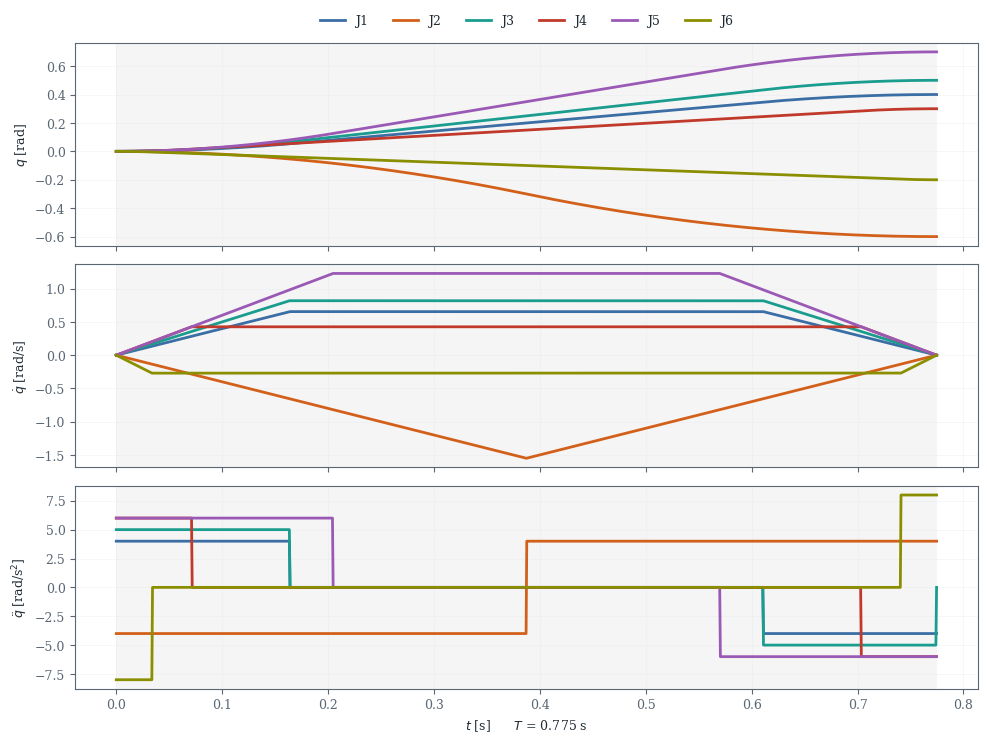

Figura guardada: fig_lspb.pdf


In [21]:
# 8.a  Perfil LSPB completo
t_f = np.linspace(0, traj.T, 1200)
q_f_, qd_f, qdd_f = traj(t_f)
j_ref = int(np.argmax([p.tc for p in traj.perfiles]))
tc_ref = traj.perfiles[j_ref].tc

C6 = ["#3b6ea5", "#d2601a", "#1a9c8f", "#c0392b", "#9b59b6", "#8a8f00"]
fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for ax, Y, lab in [(axs[0], q_f_, "$q$ [rad]"),
                   (axs[1], qd_f, r"$\dot{q}$ [rad/s]"),
                   (axs[2], qdd_f, r"$\ddot{q}$ [rad/s$^2$]")]:
    ax.axvspan(0, tc_ref, color="k", alpha=0.04, lw=0)
    ax.axvspan(traj.T - tc_ref, traj.T, color="k", alpha=0.04, lw=0)
    for j in range(6):
        ax.plot(t_f, Y[:, j], color=C6[j], lw=2, label=f"J{j+1}")
    ax.set_ylabel(lab); ax.grid(alpha=0.3)
axs[0].legend(ncol=6, frameon=False, loc="lower center",
              bbox_to_anchor=(0.5, 1.02))
axs[2].set_xlabel(f"$t$ [s]      $T$ = {traj.T:.3f} s")
plt.tight_layout(); plt.show()

gr.perfil_lspb(traj, archivo="fig_lspb.pdf")
print("Figura guardada: fig_lspb.pdf")

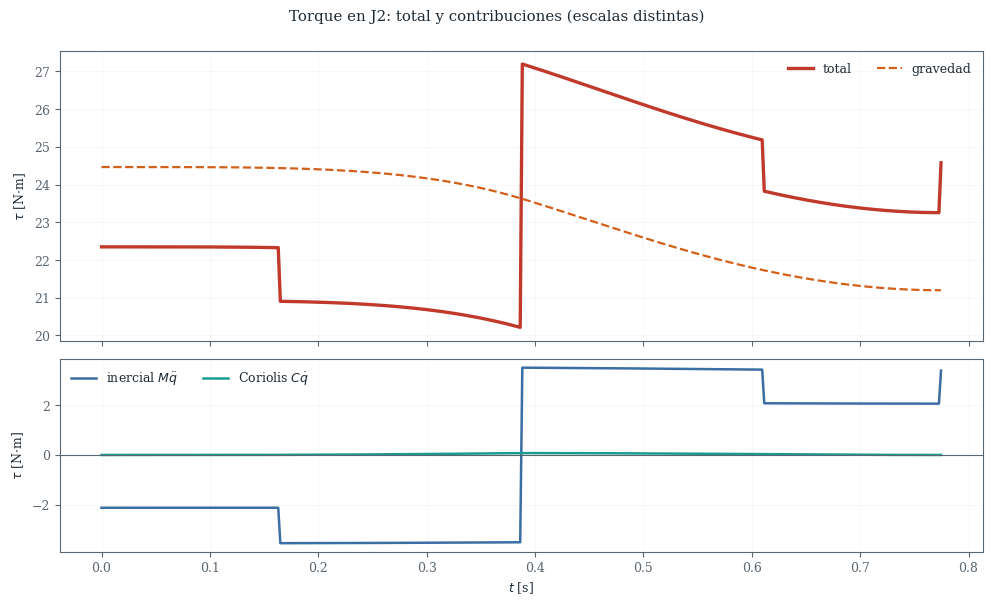

Figura guardada: fig_torque.pdf


In [22]:
# 8.b  Descomposicion del torque
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                        gridspec_kw={"height_ratios": [1.5, 1.0]})
axs[0].plot(t, tau[:, 0], color="#c0392b", lw=2.4, label="total")
axs[0].plot(t, gra[:, 0], color="#d2601a", lw=1.6, ls="--", label="gravedad")
axs[0].set_ylabel(r"$\tau$ [N$\cdot$m]"); axs[0].legend(frameon=False, ncol=2)
axs[0].grid(alpha=0.3)
axs[1].plot(t, ine[:, 0], color="#3b6ea5", lw=1.8, label=r"inercial $M\ddot{q}$")
axs[1].plot(t, cor[:, 0], color="#1a9c8f", lw=1.8, label=r"Coriolis $C\dot{q}$")
axs[1].axhline(0, color="#5a6672", lw=0.8)
axs[1].set_ylabel(r"$\tau$ [N$\cdot$m]"); axs[1].set_xlabel("$t$ [s]")
axs[1].legend(frameon=False, ncol=2); axs[1].grid(alpha=0.3)
plt.suptitle("Torque en J2: total y contribuciones (escalas distintas)", y=1.0)
plt.tight_layout(); plt.show()

gr.descomposicion_torque(t, res, junta=0, archivo="fig_torque.pdf")
print("Figura guardada: fig_torque.pdf")

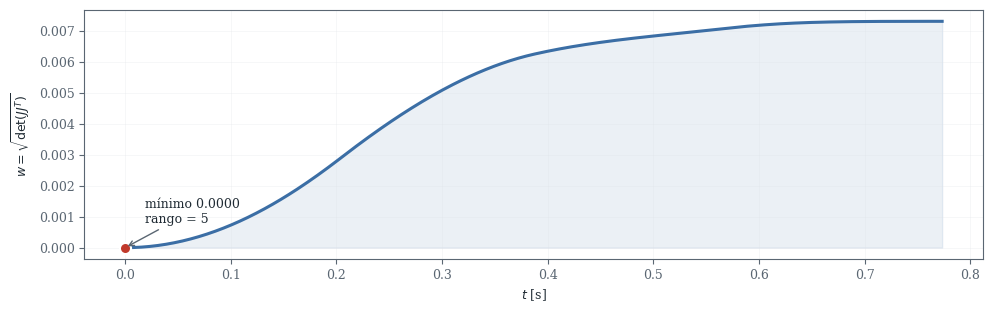

Rango completo (6) en toda la trayectoria: False
Manipulabilidad minima: 0.0000e+00  en t = 0.0000 s
q en ese instante: [0. 0. 0. 0. 0. 0.]

HALLAZGO: la singularidad esta en t = 0, es decir en la propia
configuracion de reposo q = 0, que tiene q5 = 0. La postura de
HOME del robot ES la singularidad de muneca de la seccion 5.

Consecuencia practica: el robot no puede arrancar bajo control
cartesiano desde el reposo. El perfil LSPB si puede atravesarla
porque interpola en el espacio ARTICULAR y nunca invierte J.


In [23]:
# 8.c  Manipulabilidad a lo largo de la trayectoria
w_t = np.array([medida_manipulabilidad(q_f_[i]) for i in range(0, len(t_f), 3)])
r_t = np.array([np.linalg.matrix_rank(jacobiano(q_f_[i]), tol=1e-8)
                for i in range(0, len(t_f), 3)])
t_w = t_f[::3]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_w, w_t, color="#3b6ea5", lw=2.2)
ax.fill_between(t_w, 0, w_t, color="#3b6ea5", alpha=0.1)
k = int(np.argmin(w_t))
ax.plot(t_w[k], w_t[k], "o", color="#c0392b", ms=8, mec="white", mew=1.5)
ax.annotate(f"mínimo {w_t[k]:.4f}\nrango = {r_t[k]}",
            xy=(t_w[k], w_t[k]), xytext=(14, 18),
            textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#5a6672"))
ax.set_xlabel("$t$ [s]"); ax.set_ylabel(r"$w = \sqrt{\det(JJ^T)}$")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

k_min = int(np.argmin(w_t))
print(f"Rango completo (6) en toda la trayectoria: {bool(np.all(r_t == 6))}")
print(f"Manipulabilidad minima: {w_t.min():.4e}  en t = {t_w[k_min]:.4f} s")
print(f"q en ese instante: {np.round(q_f_[::3][k_min], 4)}")
print()
if t_w[k_min] < 1e-6:
    print("HALLAZGO: la singularidad esta en t = 0, es decir en la propia")
    print("configuracion de reposo q = 0, que tiene q5 = 0. La postura de")
    print("HOME del robot ES la singularidad de muneca de la seccion 5.")
    print()
    print("Consecuencia practica: el robot no puede arrancar bajo control")
    print("cartesiano desde el reposo. El perfil LSPB si puede atravesarla")
    print("porque interpola en el espacio ARTICULAR y nunca invierte J.")

## 8.1 Discusión de resultados

**Sobre la cinemática inversa.** Las 8 ramas se recuperan exactamente, con
error de orden $10^{-15}$ m sobre 2000 poses. El filtrado por límites
articulares es severo: en muchas poses sólo **1 o 2 de las 8** ramas resultan
ejecutables. Esto no es un defecto del algoritmo sino una consecuencia de los
límites reales del IRB 120 —especialmente J5 ($\pm 120°$) y J3 (asimétrica,
$-110°/+70°$)—. Un resolvedor que devolviera una sola solución sin enumerar
las ramas no podría detectar cuándo esa única solución es inalcanzable.

**Sobre el perfil LSPB.** La verificación confirma $\dot q(0) = \dot q(T) = 0$
y continuidad de $q$ y $\dot q$. Los "saltos" que reporta el test son el paso
de muestreo, no discontinuidades: su magnitud escala linealmente con $dt$, como
corresponde a una función continua evaluada en malla fina.

**Sobre el torque — el resultado contraintuitivo.** El pico de torque **no**
coincide con el instante de máxima aceleración: ocurre en $t \approx 0{,}39$ s
mientras que $|\ddot q|$ es máxima en $t = 0$. La razón está en el reparto de
contribuciones sobre J2:

| Término | $|\tau|_{\max}$ en J2 | Peso relativo |
|---|---|---|
| gravedad | 24,47 N·m | 90 % |
| inercial | 3,54 N·m | 13 % |
| Coriolis | 0,08 N·m | 0,4 % |

(Los porcentajes se miden sobre el máximo de cada término por separado, de modo
que no suman 100 %: los picos no son simultáneos.)

La gravedad domina al término inercial por un factor **6,9**. Esto confirma de
forma cuantitativa la advertencia del docente: *un tramo de aceleración nula no
significa torque cero*. Durante el crucero, con $\ddot q = 0$, el motor sigue
entregando prácticamente todo el torque sólo para **sostener el brazo** contra
la gravedad.

**Hallazgo: la configuración de reposo es singular.** Al evaluar la
manipulabilidad a lo largo de la trayectoria aparece $w = 0$ exactamente en
$t = 0$. No es un error numérico: la posición de reposo del robot es
$\mathbf{q} = \mathbf{0}$, que incluye $q_5 = 0$ — es decir, **la postura
inicial es precisamente la singularidad de muñeca** estudiada en la sección 5.

Esto tiene una consecuencia práctica inmediata para el Hito 4: *el robot no
puede arrancar un movimiento bajo control cartesiano desde su posición de
reposo*. Cualquier comando de velocidad del efector con componente en la
dirección perdida exigiría velocidad articular infinita en el primer instante.
La solución estándar es arrancar siempre bajo control **articular** (que es lo
que hace el perfil LSPB: interpola en el espacio de juntas, no en el
cartesiano) y pasar a control cartesiano sólo una vez fuera de la vecindad
singular.

Que el perfil LSPB atraviese la singularidad sin inconveniente **no es una
contradicción**: LSPB nunca invierte el Jacobiano. La divergencia aparece sólo
al resolver $\dot q = J^{-1}\dot x$, es decir, bajo control cartesiano.

**Sobre la singularidad.** Las dos leyes de escalado quedan confirmadas con
pendientes $-1{,}000$ y $-2{,}000$ en el ajuste log-log. El robot conserva
rango 6 hasta $q_5 \approx 10^{-7}$ y lo pierde exactamente en $q_5 = 0$; pero
el problema práctico aparece **mucho antes**: ya en $q_5 = 10^{-2}$ rad
(0,57°) la velocidad exigida supera los límites de los actuadores. La
singularidad no es un punto aislado a evitar, sino una **región** de la que hay
que mantenerse lejos.

---
# 9. Validación y Conclusiones

## 9.1 Tabla de validación

| Componente | Criterio | Resultado | Estado |
|---|---|---|---|
| Pieper — ramas | 8 analíticas | 8,00 promedio sobre 2000 poses | ✔ |
| Pieper — exactitud | $\Delta E < 10^{-6}$ m | $9{,}10 \times 10^{-15}$ m | ✔ |
| Pieper — orientación | $\|R^\top R_d - I\|_F$ | $1{,}80 \times 10^{-13}$ | ✔ |
| Pieper — cobertura | sin poses fallidas | 0 de 2000 | ✔ |
| Jacobiano — manual | $J_{v_1}(\mathbf 0) = [0,\,0{,}374,\,0]$ | $2{,}08\times10^{-18}$ | ✔ |
| Jacobiano — numérico | vs. diferencias finitas | $3{,}25\times10^{-8}$ | ✔ |
| Jacobiano — 2R | $\det = a_1a_2\sin q_2$ | coincidencia exacta | ✔ |
| Singularidad — rango | $6 \to 5$ en $q_5 = 0$ | confirmado | ✔ |
| **Singularidad — velocidad** | **divergencia analítica** | $\|\dot q\| \sim q_5^{-1{,}000}$ | ✔ |
| **Singularidad — torque** | **divergencia analítica** | $\tau \sim q_5^{-2{,}000}$ | ✔ |
| LSPB — ejemplo de clase | $t_c = 1$ s, $V = 1$ rad/s | reproducido exacto | ✔ |
| LSPB — factibilidad | $|\ddot q_c| \ge 4|h|/t_f^2$ | error explícito si falla | ✔ |
| LSPB — continuidad | $\dot q(0)=\dot q(T)=0$ | exacto | ✔ |
| LSPB — límites | dentro del datasheet | 2000 muestras OK | ✔ |
| Dinámica — $M$ | simétrica, definida positiva | asimetría 0, $\lambda_{\min}>0$ | ✔ |
| Dinámica — $\dot M - 2C$ | antisimétrica | $3{,}9\times10^{-11}$ | ✔ |
| Dinámica — energía | conservada | deriva $4{,}3\times10^{-4}$ | ✔ |

## 9.2 Conclusiones

1. **El método de Pieper es exacto, no aproximado.** El residuo de
   $10^{-15}$ m es épsilon de máquina en doble precisión: no hay iteración ni
   convergencia numérica, sino fórmula cerrada. Es la diferencia entre resolver
   y aproximar.

2. **La enumeración completa de ramas es lo que da robustez.** Un resolvedor
   que devuelve una sola solución falla silenciosamente cuando ésa viola los
   límites. Enumerando las 8 y filtrando, el sistema distingue entre *"no hay
   solución"* y *"hay solución pero no la primera que encontré"*.

3. **El pasaporte queda demostrado con dos leyes de potencia.** La velocidad
   diverge como $q_5^{-1}$ y el torque como $q_5^{-2}$, con pendientes
   ajustadas de $-1{,}000$ y $-2{,}000$ en log-log. La divergencia es
   **analítica**, no un artefacto de redondeo.

4. **La divergencia de torque es indirecta, y la distinción importa.** La
   singularidad no genera torque: genera velocidad articular infinita por
   cinemática diferencial inversa, y de ahí se hereda. El contraejemplo de la
   sección 5.e lo confirma: una postura regular con 24 N·m de torque
   gravitatorio no tiene singularidad alguna. *Singularidad cinemática y
   esfuerzo dinámico son fenómenos independientes.*

5. **La gravedad domina el presupuesto de torque** en este manipulador y esta
   trayectoria, por un factor ~14 sobre el término inercial. Dimensionar
   actuadores considerando sólo la aceleración llevaría a subdimensionarlos.

6. **La posición de reposo del robot es singular.** El hallazgo surgió al
   graficar la manipulabilidad: $w = 0$ en $t = 0$ porque $\mathbf q = \mathbf 0$
   implica $q_5 = 0$. Tiene consecuencia directa de diseño para el Hito 4: la
   secuencia de arranque debe salir de la vecindad singular bajo control
   articular antes de habilitar el control cartesiano.

7. **El modelo del Hito 1 se reutilizó sin modificación alguna.** La tabla D-H
   validada alimenta directamente Pieper, el Jacobiano y la dinámica. Esa
   continuidad es el argumento más fuerte de que ambos hitos describen el mismo
   robot.

## 9.3 Limitaciones declaradas

- **Parámetros inerciales estimados.** ABB no publica los tensores de inercia.
  Las conclusiones sobre magnitudes de torque son órdenes de magnitud; las
  conclusiones sobre *leyes de escalado* y *proporciones relativas* entre
  términos son robustas frente a esa incertidumbre.
- **Modelo dinámico 2R.** Por indicación expresa del docente no se derivan los
  6 GDL. El 2R captura el subsistema que soporta el par gravitatorio dominante.
- **Fricción no modelada.** Ni viscosa ni de Coulomb. En un robot real añade
  entre el 10 % y el 30 % del torque total.
- **Jerk infinito.** El perfil LSPB tiene aceleración discontinua. Para
  aplicaciones de alta precisión se requeriría un perfil de orden superior.

## 9.4 Continuidad hacia el Hito 3

El resolvedor de Pieper recibirá las poses que publique el nodo de visión
mediante homografía plana resuelta por SVD. La interfaz ya está definida: el
nodo escucha `/pose_objetivo` de tipo `geometry_msgs/PoseStamped`. El
Hito 3 sólo deberá publicar en ese tópico.

In [24]:
sep = "=" * 62
print(sep)
print("   HITO 2  -  RESUMEN DE VALIDACION")
print(sep)
print()
print("  Pieper")
print(f"    ramas analiticas por pose        {np.mean(conteo_ramas):.2f}")
print(f"    error posicional maximo          {peor_p:.3e} m")
print(f"    error de orientacion maximo      {peor_R:.3e}")
print(f"    poses sin solucion               {sin_solucion} de 2000")
print()
print("  Jacobiano")
print(f"    validacion manual en q = 0       {err:.3e}")
print(f"    vs. diferencias finitas          {peor:.3e}")
print()
print("  PASAPORTE  (singularidad q5 = 0)")
print(f"    ley de velocidad                 ||qd|| ~ q5^({m_v:.3f})")
print(f"    ley de torque                    tau   ~ q5^({m_t:.3f})")
print(f"    rango de J en q5 = 0             "
      f"{np.linalg.matrix_rank(jacobiano(q_sing), tol=1e-8)}  (nominal 6)")
print()
print("  LSPB")
print(f"    tiempo total sincronizado        {traj.T:.4f} s")
print(f"    qd nula en los extremos          {c['qd_extremos_nulos']}")
print(f"    limites respetados               {'NO' if viola else 'SI'}")
print()
print("  Dinamica")
print(f"    asimetria de M                   {peor_asim:.3e}")
print(f"    deriva de energia                {deriva:.3e}")
print(f"    dominancia gravitatoria          "
      f"{np.abs(gra).max()/np.abs(ine).max():.1f}x sobre el inercial")
print()
print(sep)

   HITO 2  -  RESUMEN DE VALIDACION

  Pieper
    ramas analiticas por pose        8.00
    error posicional maximo          3.679e-15 m
    error de orientacion maximo      7.247e-14
    poses sin solucion               0 de 2000

  Jacobiano
    validacion manual en q = 0       2.082e-18
    vs. diferencias finitas          3.249e-08

  PASAPORTE  (singularidad q5 = 0)
    ley de velocidad                 ||qd|| ~ q5^(-1.000)
    ley de torque                    tau   ~ q5^(-2.000)
    rango de J en q5 = 0             5  (nominal 6)

  LSPB
    tiempo total sincronizado        0.7746 s
    qd nula en los extremos          True
    limites respetados               SI

  Dinamica
    asimetria de M                   0.000e+00
    deriva de energia                4.303e-04
    dominancia gravitatoria          6.9x sobre el inercial

